عنوان پروژه: سامانه پایش و تحلیل کیفیت هوا

In [1]:
import numpy as np

In [2]:
import pandas as pd

In [3]:
import matplotlib.pyplot as plt

In [4]:
import seaborn as sns

In [19]:
from sklearn.preprocessing import MinMaxScaler

In [5]:
weather_data = pd.read_csv('weather_data.csv')
pollution_data = pd.read_excel('air_quality.xlsx')

In [6]:
weather_data.shape

(366, 9)

In [7]:
weather_data.columns

Index(['date', 'city', 'temperature_max', 'temperature_min', 'temperature_avg',
       'humidity', 'wind_speed', 'precipitation', 'weather_condition'],
      dtype='object')

In [8]:
weather_data.head()

,date,city,temperature_max,temperature_min,temperature_avg,humidity,wind_speed,precipitation,weather_condition
0,2024-01-01,Tehran,9.6,1.7,5.3,66,2.6,0.3,Cloudy
1,2024-01-02,Tehran,8.0,-1.7,4.0,64,6.1,0.2,Cloudy
2,2024-01-03,Tehran,9.6,2.6,5.5,66,1.5,0.0,Cloudy
3,2024-01-04,Tehran,10.5,3.7,7.2,41,5.6,0.0,Cloudy
4,2024-01-05,Tehran,7.7,-0.1,3.7,75,3.7,0.2,Cloudy


In [9]:
pollution_data.shape

(366, 10)

In [10]:
pollution_data.columns

Index(['date', 'city', 'PM2_5', 'PM10', 'NO2', 'O3', 'CO', 'SO2', 'AQI',
       'AQI_Category'],
      dtype='object')

In [11]:
pollution_data.head()

,date,city,PM2_5,PM10,NO2,O3,CO,SO2,AQI,AQI_Category
0,2024-01-01,Tehran,55.9,91.7,79.8,5.0,2.9,11,134,Unhealthy for Sensitive Groups
1,2024-01-02,Tehran,50.1,77.7,73.8,5.0,2.9,20,122,Unhealthy for Sensitive Groups
2,2024-01-03,Tehran,60.3,102.2,68.3,5.0,2.3,14,144,Unhealthy for Sensitive Groups
3,2024-01-04,Tehran,48.5,75.6,74.8,14.5,1.9,10,118,Unhealthy for Sensitive Groups
4,2024-01-05,Tehran,55.6,99.1,69.3,5.0,2.5,18,134,Unhealthy for Sensitive Groups


In [12]:
weather_data['date'] = pd.to_datetime(weather_data['date'])
pollution_data['date'] = pd.to_datetime(pollution_data['date'])

In [13]:
merged_data = pd.merge(
    weather_data,
    pollution_data,
    on=['date', 'city'],
    how='inner'
)

In [14]:
merged_data.shape

(366, 17)

In [15]:
merged_data.head()

,date,city,temperature_max,temperature_min,temperature_avg,humidity,wind_speed,precipitation,weather_condition,PM2_5,PM10,NO2,O3,CO,SO2,AQI,AQI_Category
0,2024-01-01,Tehran,9.6,1.7,5.3,66,2.6,0.3,Cloudy,55.9,91.7,79.8,5.0,2.9,11,134,Unhealthy for Sensitive Groups
1,2024-01-02,Tehran,8.0,-1.7,4.0,64,6.1,0.2,Cloudy,50.1,77.7,73.8,5.0,2.9,20,122,Unhealthy for Sensitive Groups
2,2024-01-03,Tehran,9.6,2.6,5.5,66,1.5,0.0,Cloudy,60.3,102.2,68.3,5.0,2.3,14,144,Unhealthy for Sensitive Groups
3,2024-01-04,Tehran,10.5,3.7,7.2,41,5.6,0.0,Cloudy,48.5,75.6,74.8,14.5,1.9,10,118,Unhealthy for Sensitive Groups
4,2024-01-05,Tehran,7.7,-0.1,3.7,75,3.7,0.2,Cloudy,55.6,99.1,69.3,5.0,2.5,18,134,Unhealthy for Sensitive Groups


In [16]:
merged_data.isnull().sum()

date                 0
city                 0
temperature_max      0
temperature_min      0
temperature_avg      0
humidity             0
wind_speed           0
precipitation        0
weather_condition    0
PM2_5                0
PM10                 0
NO2                  0
O3                   0
CO                   0
SO2                  0
AQI                  0
AQI_Category         0
dtype: int64

In [17]:
num_cols = merged_data.select_dtypes(include='number').columns

for col in num_cols:
    q1 = merged_data[col].quantile(0.25)
    q3 = merged_data[col].quantile(0.75)
    iqr = q3 - q1

    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr

    outliers = merged_data[(merged_data[col] < low) | (merged_data[col] > high)]

    print(col, len(outliers))

temperature_max 0
temperature_min 0
temperature_avg 0
humidity 0
wind_speed 11
precipitation 68
PM2_5 0
PM10 0
NO2 0
O3 0
CO 0
SO2 0
AQI 0


In [18]:
merged_data[['wind_speed', 'precipitation']].describe()

,wind_speed,precipitation
count,366.000000,366.000000
mean,5.020765,0.172678
std,3.060568,0.430758
min,1.000000,0.000000
25%,2.700000,0.000000
50%,4.400000,0.000000
75%,6.600000,0.100000
max,17.600000,2.800000


In [20]:
scale_columns = [
    'temperature_max',
    'temperature_min',
    'temperature_avg',
    'humidity',
    'wind_speed',
    'precipitation',
    'PM2_5',
    'PM10',
    'NO2',
    'O3',
    'CO',
    'SO2',
    'AQI'
]

scaler = MinMaxScaler()

merged_data[scale_columns] = scaler.fit_transform(
    merged_data[scale_columns]
)

In [21]:
merged_data[scale_columns].head()

,temperature_max,temperature_min,temperature_avg,humidity,wind_speed,precipitation,PM2_5,PM10,NO2,O3,CO,SO2,AQI
0,0.164456,0.154412,0.130435,0.803030,0.096386,0.107143,0.848333,0.750230,0.959893,0.000000,0.8125,0.421053,0.847328
1,0.122016,0.071078,0.097187,0.772727,0.307229,0.071429,0.751667,0.621671,0.879679,0.000000,0.8125,0.894737,0.755725
2,0.164456,0.176471,0.135550,0.803030,0.030120,0.000000,0.921667,0.846648,0.806150,0.000000,0.6250,0.578947,0.923664
3,0.188329,0.203431,0.179028,0.424242,0.277108,0.000000,0.725000,0.602388,0.893048,0.131215,0.5000,0.368421,0.725191
4,0.114058,0.110294,0.089514,0.939394,0.162651,0.071429,0.843333,0.818182,0.819519,0.000000,0.6875,0.789474,0.847328


In [22]:
merged_data['date'] = pd.to_datetime(merged_data['date'])

merged_data['month'] = merged_data['date'].dt.month

merged_data['season'] = merged_data['month'].map({
    12: 'Winter',
    1: 'Winter',
    2: 'Winter',
    3: 'Spring',
    4: 'Spring',
    5: 'Spring',
    6: 'Summer',
    7: 'Summer',
    8: 'Summer',
    9: 'Autumn',
    10: 'Autumn',
    11: 'Autumn'
})

In [23]:
merged_data[['date', 'month', 'season']].head(10)

,date,month,season
0,2024-01-01,1,Winter
1,2024-01-02,1,Winter
2,2024-01-03,1,Winter
3,2024-01-04,1,Winter
4,2024-01-05,1,Winter
5,2024-01-06,1,Winter
6,2024-01-07,1,Winter
7,2024-01-08,1,Winter
8,2024-01-09,1,Winter
9,2024-01-10,1,Winter


In [24]:
season_aqi = merged_data.groupby('season')['AQI'].mean()
season_aqi

season
Autumn    0.415318
Spring    0.318453
Summer    0.064388
Winter    0.726533
Name: AQI, dtype: float64

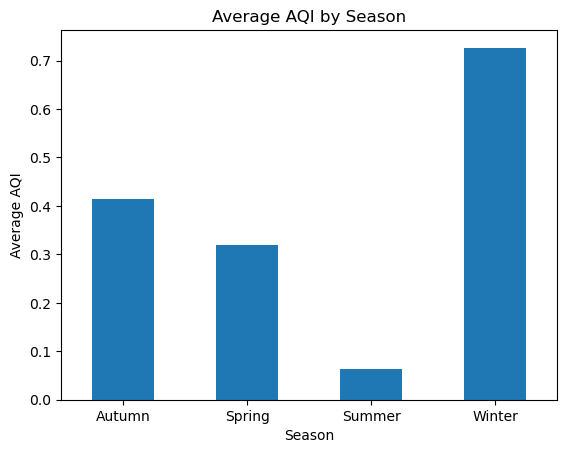

In [25]:
season_aqi.plot(kind='bar')

plt.title('Average AQI by Season')
plt.xlabel('Season')
plt.ylabel('Average AQI')
plt.xticks(rotation=0)
plt.show()

In [26]:
corr = merged_data[
    ['temperature_avg', 'humidity', 'wind_speed', 'PM2_5', 'PM10', 'NO2', 'O3', 'CO', 'SO2', 'AQI']
].corr()

corr

,temperature_avg,humidity,wind_speed,PM2_5,PM10,NO2,O3,CO,SO2,AQI
temperature_avg,1.000000,-0.903833,-0.025476,-0.914632,-0.884416,-0.944252,0.938008,-0.879220,-0.007587,-0.914764
humidity,-0.903833,1.000000,-0.015950,0.836489,0.817522,0.860053,-0.840229,0.790509,0.012101,0.836494
wind_speed,-0.025476,-0.015950,1.000000,-0.035607,-0.031670,0.030488,-0.006184,0.022376,-0.096174,-0.035450
PM2_5,-0.914632,0.836489,-0.035607,1.000000,0.965912,0.909795,-0.897291,0.818880,0.002463,0.999966
PM10,-0.884416,0.817522,-0.031670,0.965912,1.000000,0.876059,-0.860682,0.786344,0.017823,0.965883
NO2,-0.944252,0.860053,0.030488,0.909795,0.876059,1.000000,-0.923176,0.869916,0.006146,0.910024
O3,0.938008,-0.840229,-0.006184,-0.897291,-0.860682,-0.923176,1.000000,-0.855221,-0.008478,-0.897338
CO,-0.879220,0.790509,0.022376,0.818880,0.786344,0.869916,-0.855221,1.000000,-0.027948,0.819193
SO2,-0.007587,0.012101,-0.096174,0.002463,0.017823,0.006146,-0.008478,-0.027948,1.000000,0.002011
AQI,-0.914764,0.836494,-0.035450,0.999966,0.965883,0.910024,-0.897338,0.819193,0.002011,1.000000


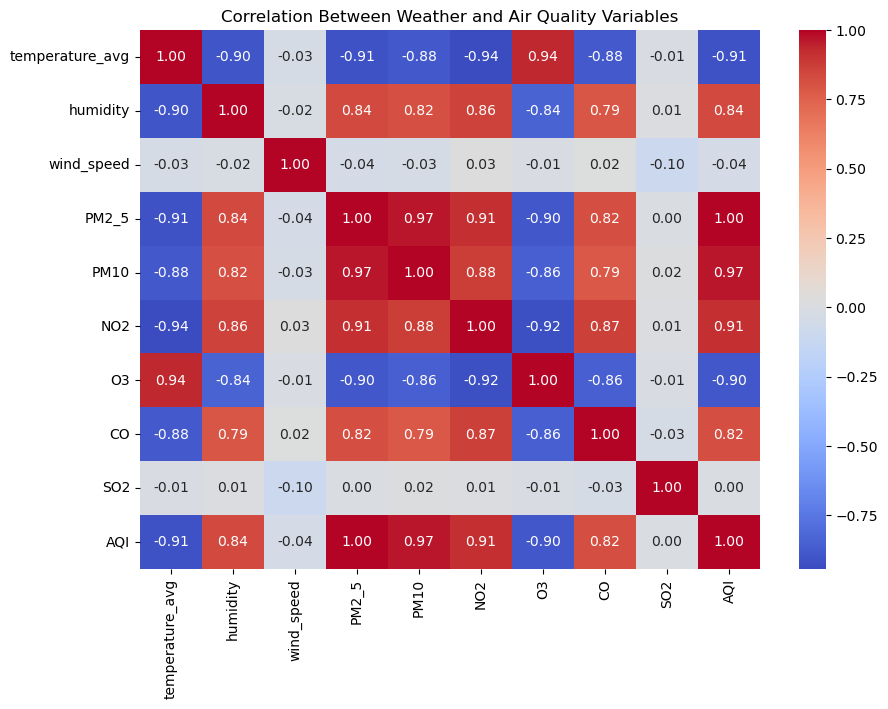

In [27]:
corr = merged_data[
    ['temperature_avg', 'humidity', 'wind_speed',
     'PM2_5', 'PM10', 'NO2', 'O3', 'CO', 'SO2', 'AQI']
].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Between Weather and Air Quality Variables')
plt.show()

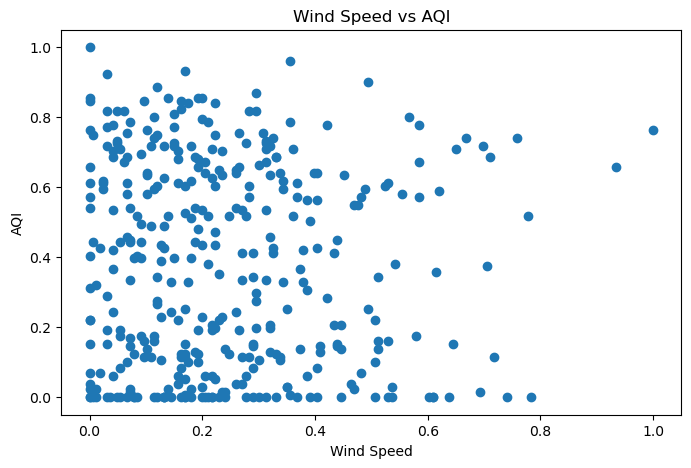

In [28]:
plt.figure(figsize=(8, 5))

plt.scatter(merged_data['wind_speed'], merged_data['AQI'])

plt.title('Wind Speed vs AQI')
plt.xlabel('Wind Speed')
plt.ylabel('AQI')

plt.show()

In [30]:
pollutants = ['PM2_5', 'PM10', 'NO2', 'O3', 'CO', 'SO2']

pollutant_corr = merged_data[pollutants + ['AQI']].corr()['AQI'].drop('AQI')

pollutant_corr.sort_values(ascending=False)

PM2_5    0.999966
PM10     0.965883
NO2      0.910024
CO       0.819193
SO2      0.002011
O3      -0.897338
Name: AQI, dtype: float64

In [31]:
weather_corr = merged_data[
    ['temperature_avg', 'humidity', 'wind_speed', 'AQI']
].corr()['AQI'].drop('AQI')

weather_corr.sort_values(ascending=False)

humidity           0.836494
wind_speed        -0.035450
temperature_avg   -0.914764
Name: AQI, dtype: float64

In [32]:
critical_days = merged_data[
    merged_data['AQI'] > merged_data['AQI'].quantile(0.90)
]

critical_days[['date', 'AQI', 'PM2_5', 'PM10', 'NO2']].sort_values(
    by='AQI',
    ascending=False
).head(10)

,date,AQI,PM2_5,PM10,NO2
14,2024-01-15,1.000000,1.000000,0.916437,0.751337
45,2024-02-15,0.961832,0.955000,1.000000,0.875668
29,2024-01-30,0.931298,0.926667,0.916437,0.903743
2,2024-01-03,0.923664,0.921667,0.846648,0.806150
15,2024-01-16,0.900763,0.901667,0.768595,0.918449
11,2024-01-12,0.885496,0.880000,0.736455,0.824866
56,2024-02-26,0.870229,0.866667,0.752984,0.775401
55,2024-02-25,0.854962,0.850000,0.720845,0.844920
80,2024-03-21,0.854962,0.848333,0.628099,0.572193
324,2024-11-20,0.854962,0.855000,0.773186,0.669786


In [33]:
merged_data['risk_level'] = pd.cut(
    merged_data['AQI'],
    bins=[-1, 0.33, 0.66, 1],
    labels=['Low', 'Medium', 'High']
)

merged_data['risk_level'].value_counts()

risk_level
Low       170
Medium    114
High       82
Name: count, dtype: int64

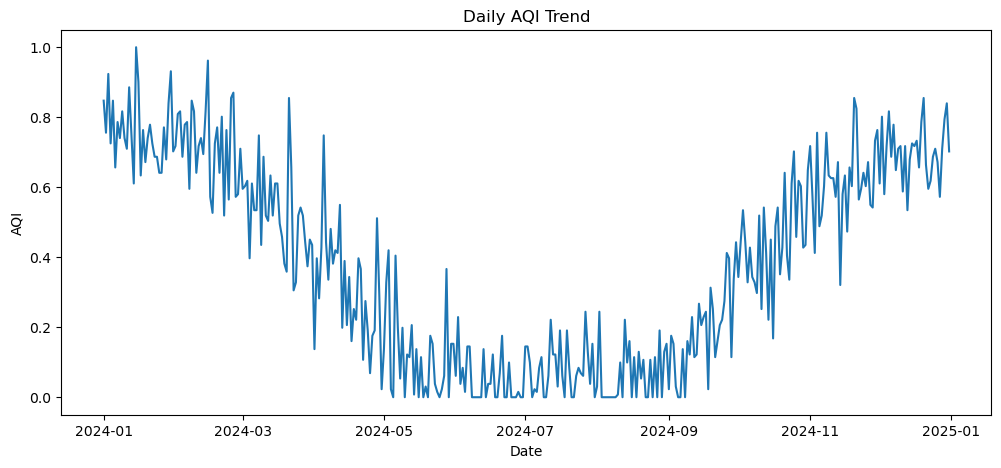

In [34]:
daily_aqi = merged_data.groupby('date')['AQI'].mean()

plt.figure(figsize=(12, 5))

plt.plot(daily_aqi)

plt.title('Daily AQI Trend')
plt.xlabel('Date')
plt.ylabel('AQI')

plt.show()

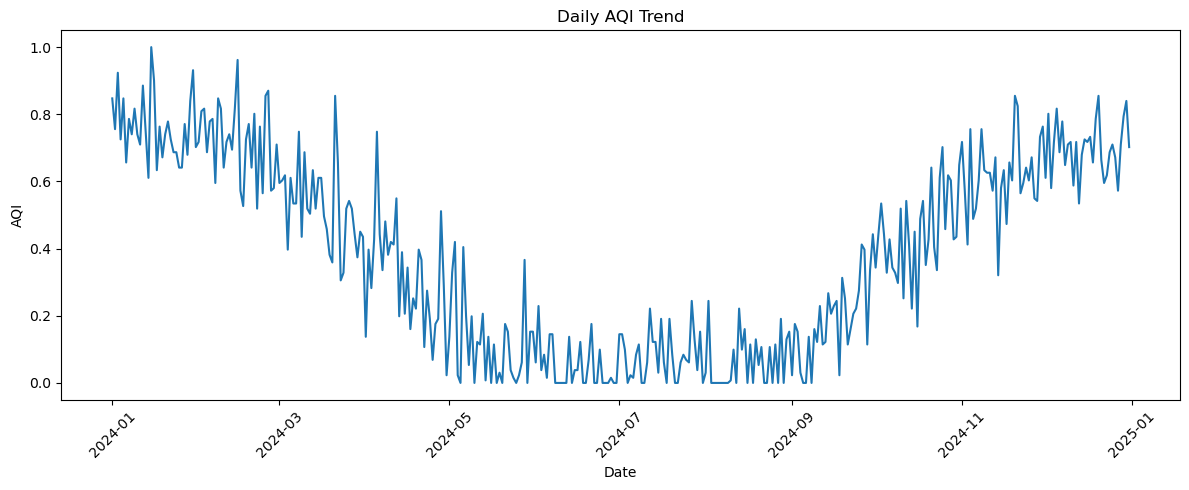

In [35]:
plt.figure(figsize=(12, 5))

plt.plot(merged_data['date'], merged_data['AQI'])

plt.title('Daily AQI Trend')
plt.xlabel('Date')
plt.ylabel('AQI')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

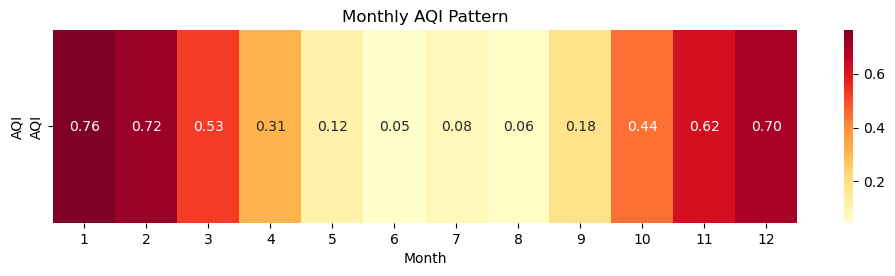

In [36]:
monthly_aqi = merged_data.groupby('month')['AQI'].mean()

heatmap_data = monthly_aqi.to_frame().T

plt.figure(figsize=(12, 2.5))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.2f',
    cmap='YlOrRd'
)

plt.title('Monthly AQI Pattern')
plt.xlabel('Month')
plt.ylabel('AQI')

plt.show()


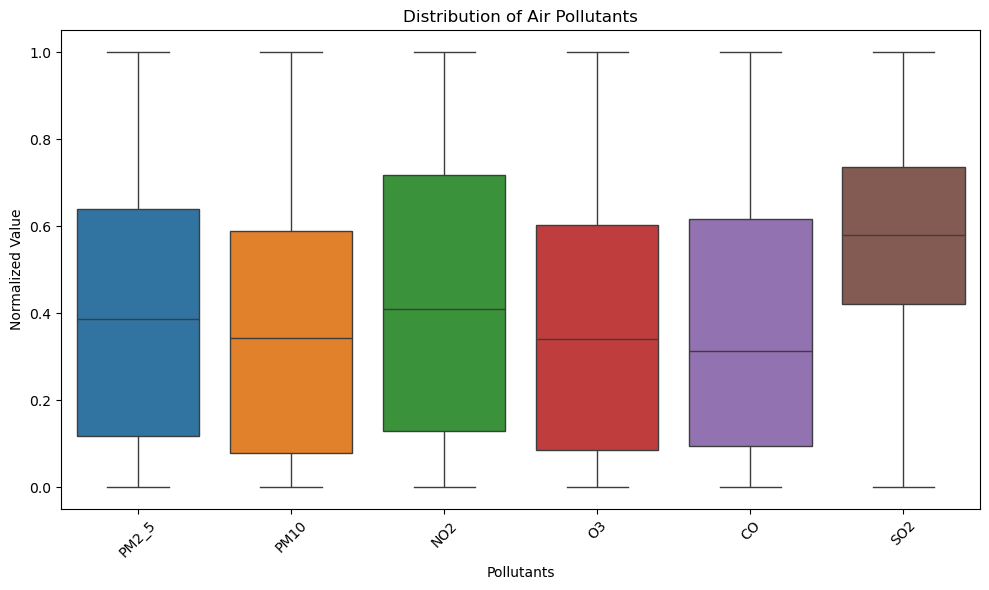

In [37]:
pollutants = ['PM2_5', 'PM10', 'NO2', 'O3', 'CO', 'SO2']

plt.figure(figsize=(10, 6))

sns.boxplot(data=merged_data[pollutants])

plt.title('Distribution of Air Pollutants')
plt.xlabel('Pollutants')
plt.ylabel('Normalized Value')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [38]:
top_5_days = merged_data[
    ['date', 'AQI', 'PM2_5', 'PM10', 'NO2']
].sort_values(
    by='AQI',
    ascending=False
).head(5)

top_5_days

,date,AQI,PM2_5,PM10,NO2
14,2024-01-15,1.000000,1.000000,0.916437,0.751337
45,2024-02-15,0.961832,0.955000,1.000000,0.875668
29,2024-01-30,0.931298,0.926667,0.916437,0.903743
2,2024-01-03,0.923664,0.921667,0.846648,0.806150
15,2024-01-16,0.900763,0.901667,0.768595,0.918449


In [39]:
merged_data['warning'] = pd.cut(
    merged_data['AQI'],
    bins=[-1, 0.33, 0.66, 1],
    labels=['Normal', 'Warning', 'Critical']
)

merged_data[['date', 'AQI', 'warning']].head()

,date,AQI,warning
0,2024-01-01,0.847328,Critical
1,2024-01-02,0.755725,Critical
2,2024-01-03,0.923664,Critical
3,2024-01-04,0.725191,Critical
4,2024-01-05,0.847328,Critical


In [40]:
merged_data['warning'].value_counts()

warning
Normal      170
Warning     114
Critical     82
Name: count, dtype: int64

In [41]:
def air_quality_warning(aqi):
    if aqi <= 0.33:
        return "Normal"
    elif aqi <= 0.66:
        return "Warning"
    else:
        return "Critical"

In [42]:
air_quality_warning(0.8)

'Critical'

In [43]:
'Critical'

'Critical'

In [44]:
merged_data['auto_warning'] = merged_data['AQI'].apply(air_quality_warning)

In [45]:
merged_data[['date', 'AQI', 'auto_warning']].head()


,date,AQI,auto_warning
0,2024-01-01,0.847328,Critical
1,2024-01-02,0.755725,Critical
2,2024-01-03,0.923664,Critical
3,2024-01-04,0.725191,Critical
4,2024-01-05,0.847328,Critical


In [46]:
merged_data[['date', 'AQI', 'auto_warning']].sort_values(
    by='AQI',
    ascending=False
).head(10)

,date,AQI,auto_warning
14,2024-01-15,1.000000,Critical
45,2024-02-15,0.961832,Critical
29,2024-01-30,0.931298,Critical
2,2024-01-03,0.923664,Critical
15,2024-01-16,0.900763,Critical
11,2024-01-12,0.885496,Critical
56,2024-02-26,0.870229,Critical
324,2024-11-20,0.854962,Critical
80,2024-03-21,0.854962,Critical
354,2024-12-20,0.854962,Critical


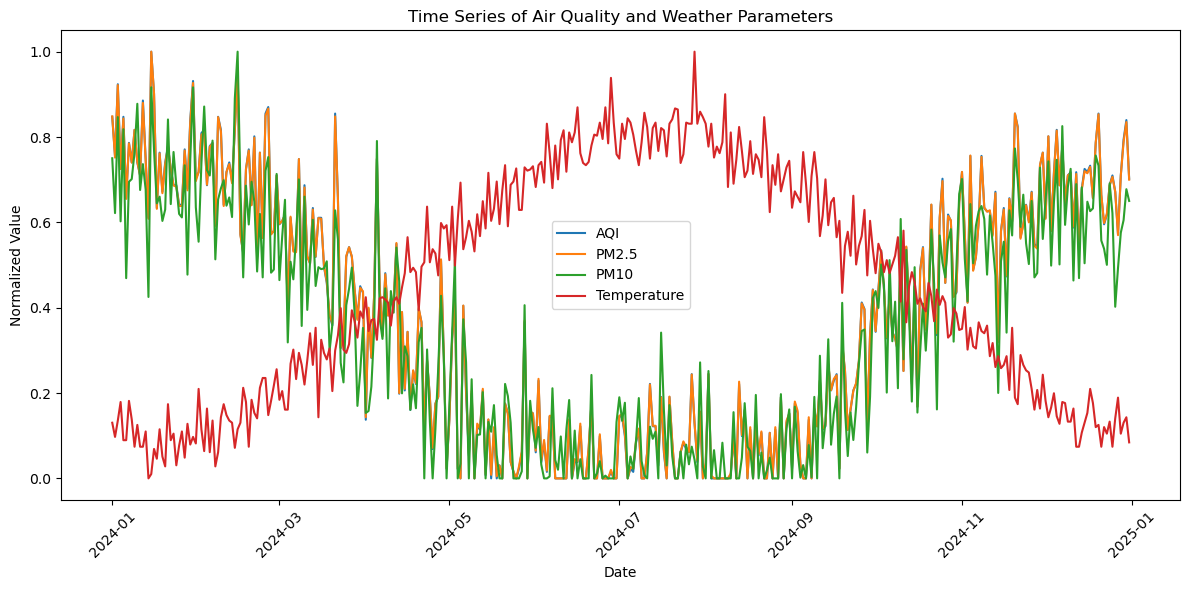

In [47]:
plt.figure(figsize=(12, 6))

plt.plot(merged_data['date'], merged_data['AQI'], label='AQI')
plt.plot(merged_data['date'], merged_data['PM2_5'], label='PM2.5')
plt.plot(merged_data['date'], merged_data['PM10'], label='PM10')
plt.plot(merged_data['date'], merged_data['temperature_avg'], label='Temperature')

plt.title('Time Series of Air Quality and Weather Parameters')
plt.xlabel('Date')
plt.ylabel('Normalized Value')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# گزارش تحلیل کیفیت هوا

 دوره بررسی: سال 2024
 تعداد داده‌ها: 366 رکورد
 تعداد متغیرها: 17
 داده گمشده: ندارد
 آلوده‌ترین فصل: زمستان
 کم‌آلودگی‌ترین فصل: تابستان
 مهم‌ترین آلاینده‌های مرتبط با AQI: PM2.5، PM10 و NO2
 بیشترین AQI: مربوط به 15 ژانویه 2024

# شناسایی بحرانی‌ترین دوره‌های آلودگی

 بیشترین AQI: 15 ژانویه 2024
 مقدار AQI نرمال‌شده: 1.0000
 دومین روز: 15 فوریه 2024
 5 روز از بحرانی‌ترین روزها: 4 مورد در ماه ژانویه
 سطح هشدار: Critical

# تحلیل تأثیر پارامترهای جوی بر آلودگی

رطوبت: رابطه مثبت قوی با AQI    0.8365
  دمای متوسط: رابطه منفی بسیار قوی با AQI     -0.9148
  سرعت باد: رابطه خطی بسیار ضعیف با AQI    -0.0355
 نتیجه: دما و رطوبت در این داده‌ها ارتباط قابل‌توجه‌تری با AQI داشتند
 

# سیستم هشدار خودکار

 Normal: 170 روز
 Warning: 114 روز
 Critical: 82 روز
 روش: دسته‌بندی AQI نرمال‌شده در سه سطح
 هدف: شناسایی سریع روزهای دارای ریسک بالاتر آلودگی